This file represents the main Google Colab Notebook (interactive training & visualization)

Modified from Google Research Google Colab mathwriting_code_examples.ipynb

## Starter Code

In [7]:
import dataclasses
import json
import os
import pprint
import re

import numpy as np
%pip -q install matplotlib
import matplotlib.pyplot as pl
import matplotlib.patches as mpl_patches

from xml.etree import ElementTree


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
!wget -nc https://storage.googleapis.com/mathwriting_data/mathwriting-2024-excerpt.tgz
!tar zxf mathwriting-2024-excerpt.tgz
!ls mathwriting-2024-excerpt

MATHWRITING_ROOT_DIR='mathwriting-2024-excerpt'

zsh:1: command not found: wget
tar: mathwriting-2024-excerpt.tgz: m: No such file or directory
ls: mathwriting-2024-excerpt: No such file or directory


## Reading InkML files

All inks are provided in InkML format. The code below shows how to read the specific structure used by MathWriting.

In [10]:
@dataclasses.dataclass
class Ink:
  """Represents a single ink, as read from an InkML file."""
  # Every stroke in the ink.
  # Each stroke array has shape (3, number of points), where the first
  # dimensions are (x, y, timestamp), in that order.
  strokes: list[np.ndarray]
  # Metadata present in the InkML.
  annotations: dict[str, str]


def read_inkml_file(filename: str) -> Ink:
  """Simple reader for MathWriting's InkML files."""
  with open(filename, "r") as f:
    root = ElementTree.fromstring(f.read())

  strokes = []
  annotations = {}

  for element in root:
    tag_name = element.tag.removeprefix('{http://www.w3.org/2003/InkML}')
    if tag_name == 'annotation':
      annotations[element.attrib.get('type')] = element.text

    elif tag_name == 'trace':
      points = element.text.split(',')
      stroke_x, stroke_y, stroke_t = [], [], []
      for point in points:
        x, y, t = point.split(' ')
        stroke_x.append(float(x))
        stroke_y.append(float(y))
        stroke_t.append(float(t))
      strokes.append(np.array((stroke_x, stroke_y, stroke_t)))

  return Ink(strokes=strokes, annotations=annotations)


def display_ink(
    ink: Ink,
    *,
    figsize: tuple[int, int]=(15, 10),
    linewidth: int=2,
    color=None):
  """Simple display for a single ink."""
  pl.figure(figsize=figsize)
  for stroke in ink.strokes:
    pl.plot(stroke[0], stroke[1], linewidth=linewidth, color=color)
    pl.title(
        f"{ink.annotations.get('sampleId', '')} -- "
        f"{ink.annotations.get('splitTagOriginal', '')} -- "
        f"{ink.annotations.get('normalizedLabel', ink.annotations['label'])}"
    )
  pl.gca().invert_yaxis()
  pl.gca().axis('equal')

Displays

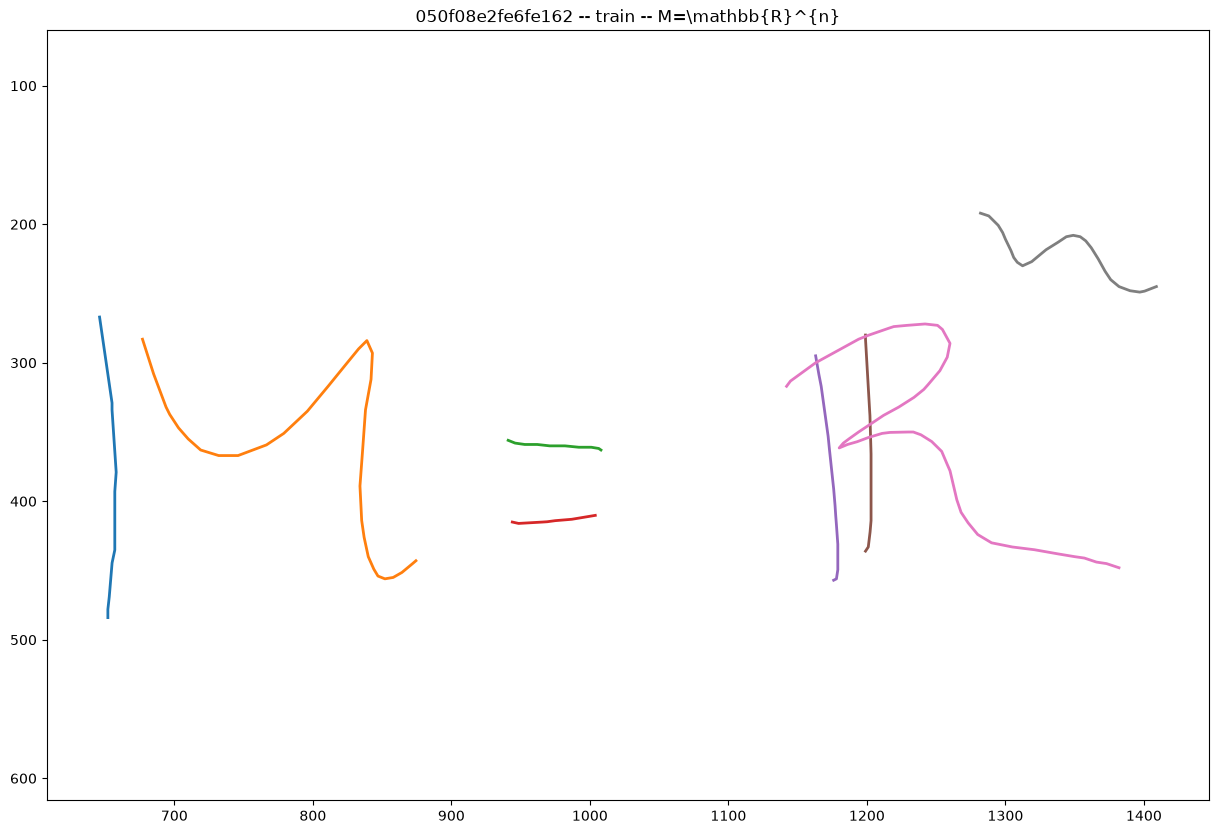

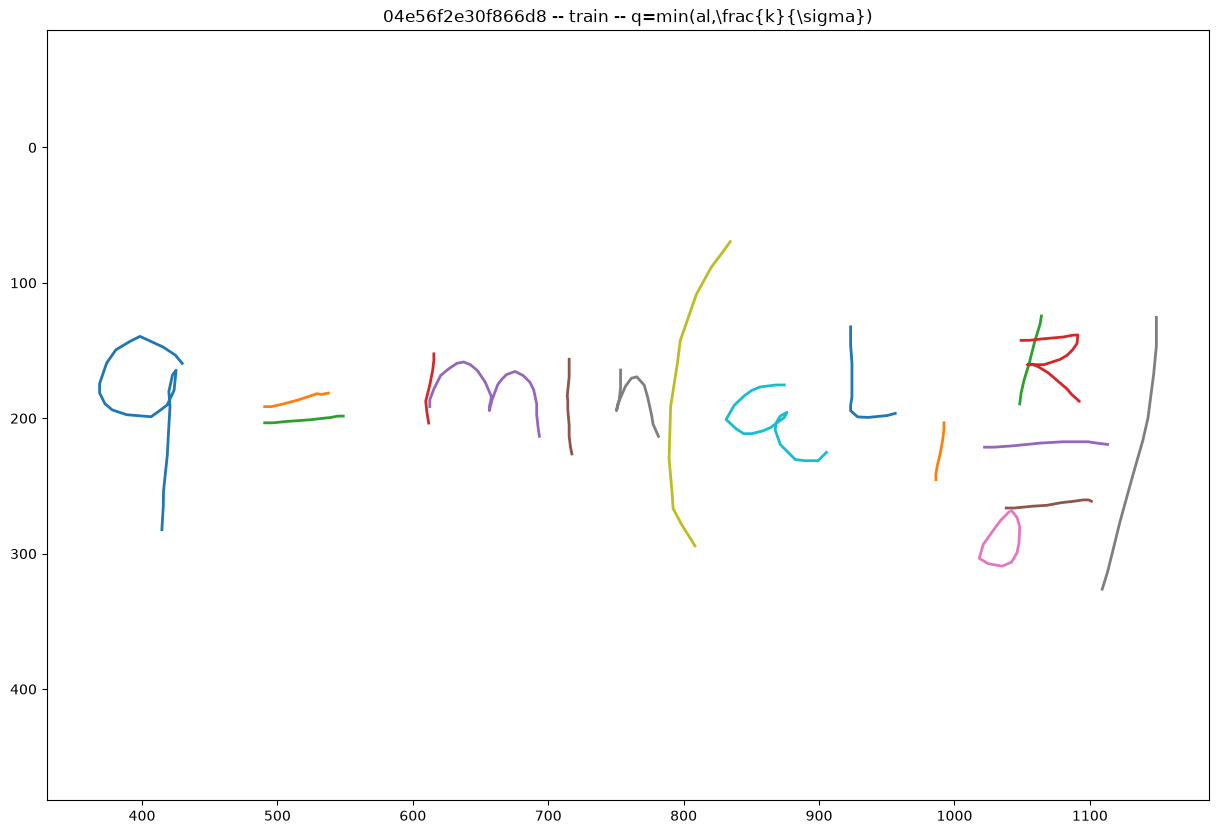

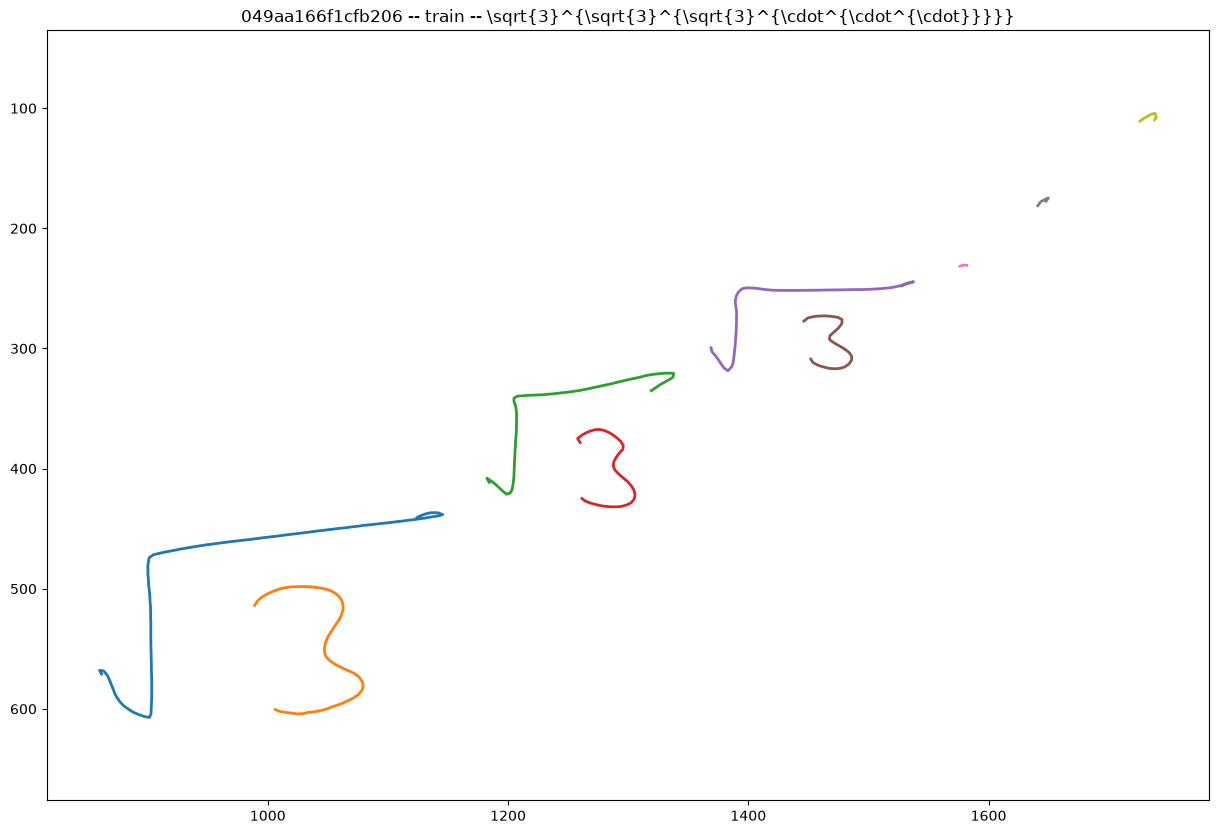

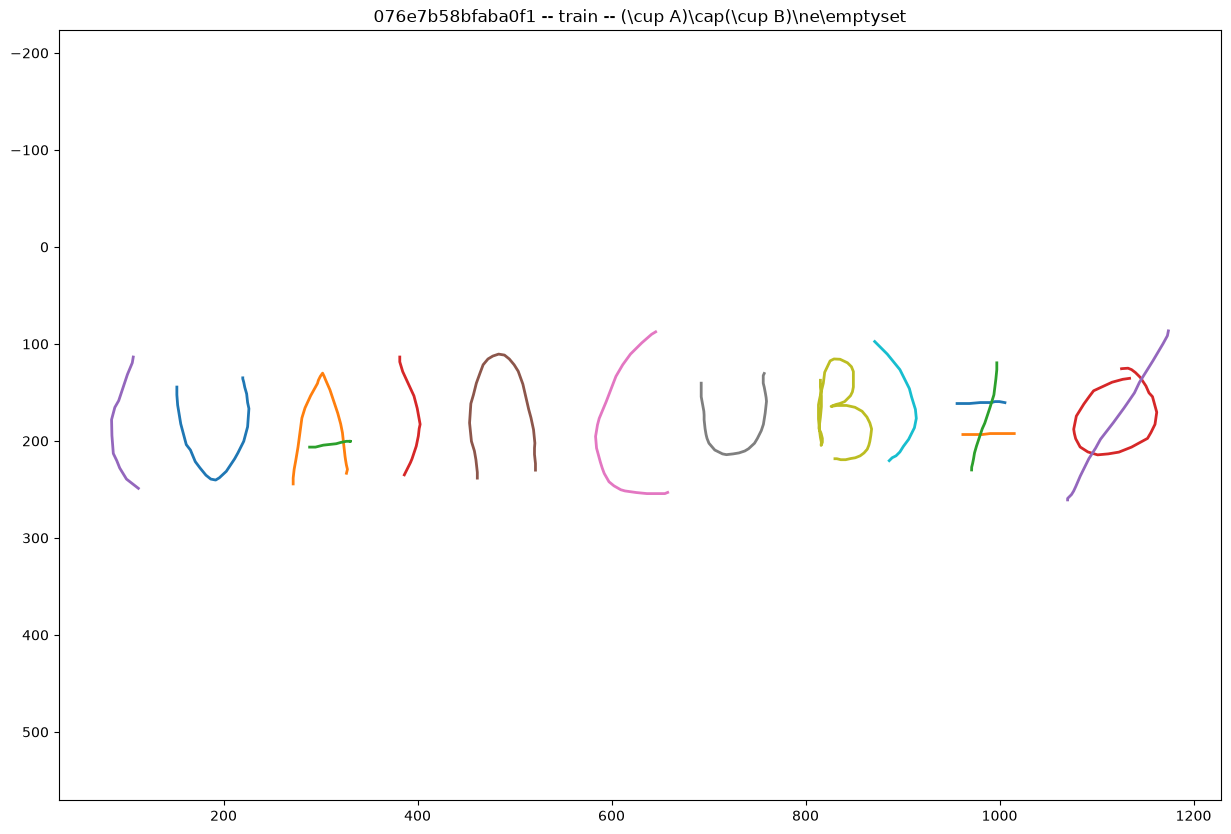

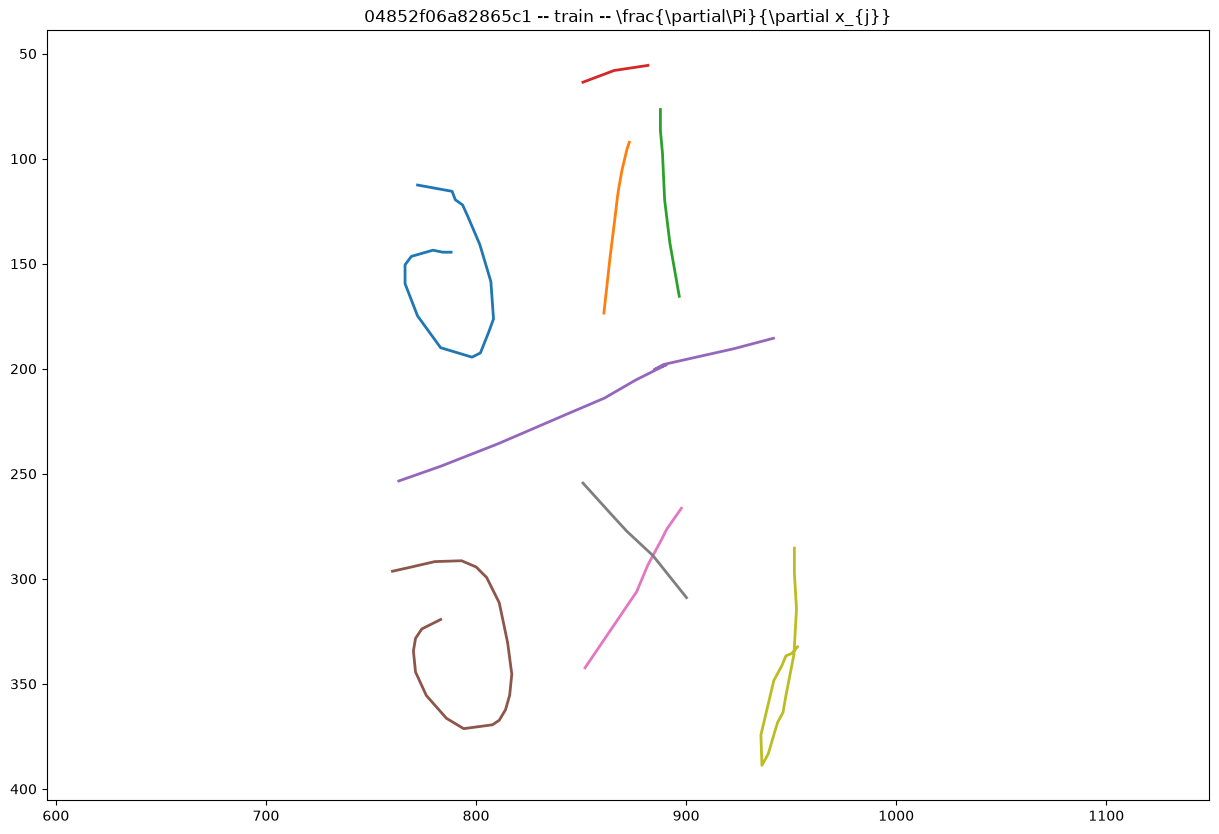

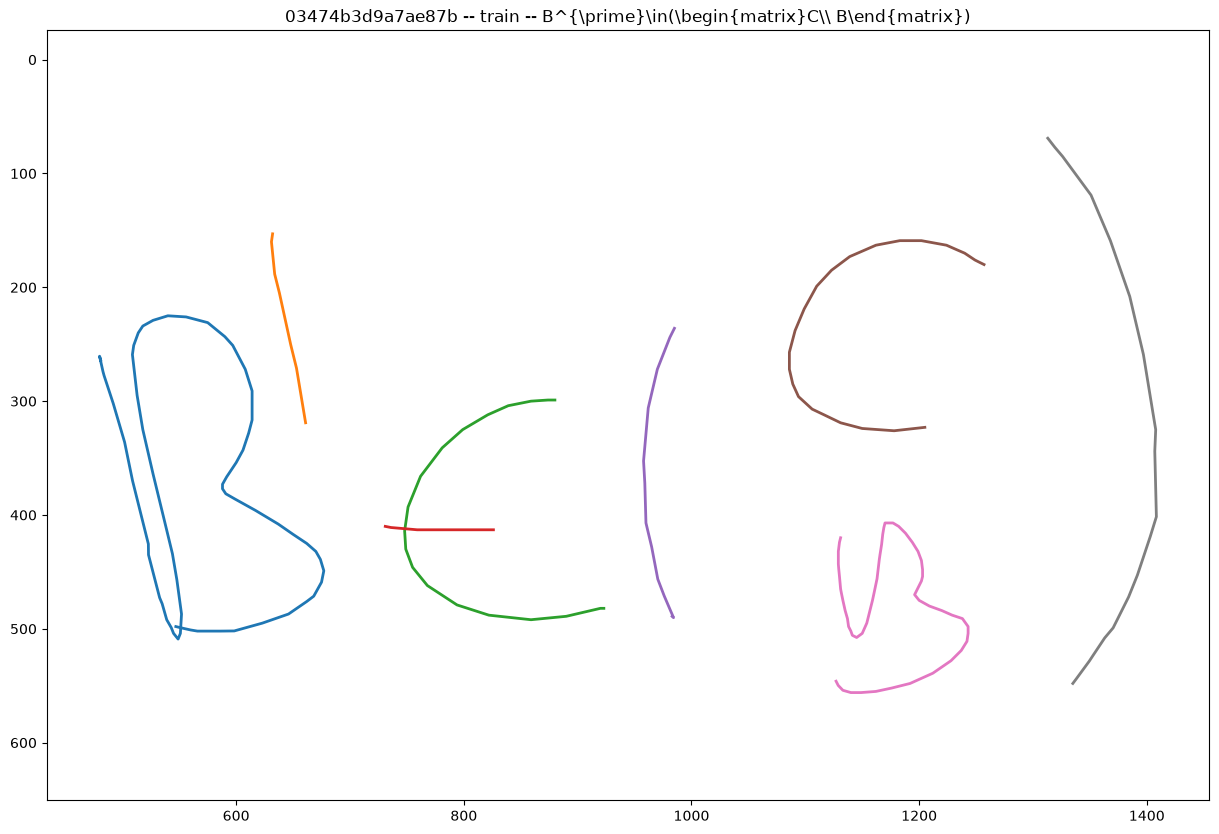

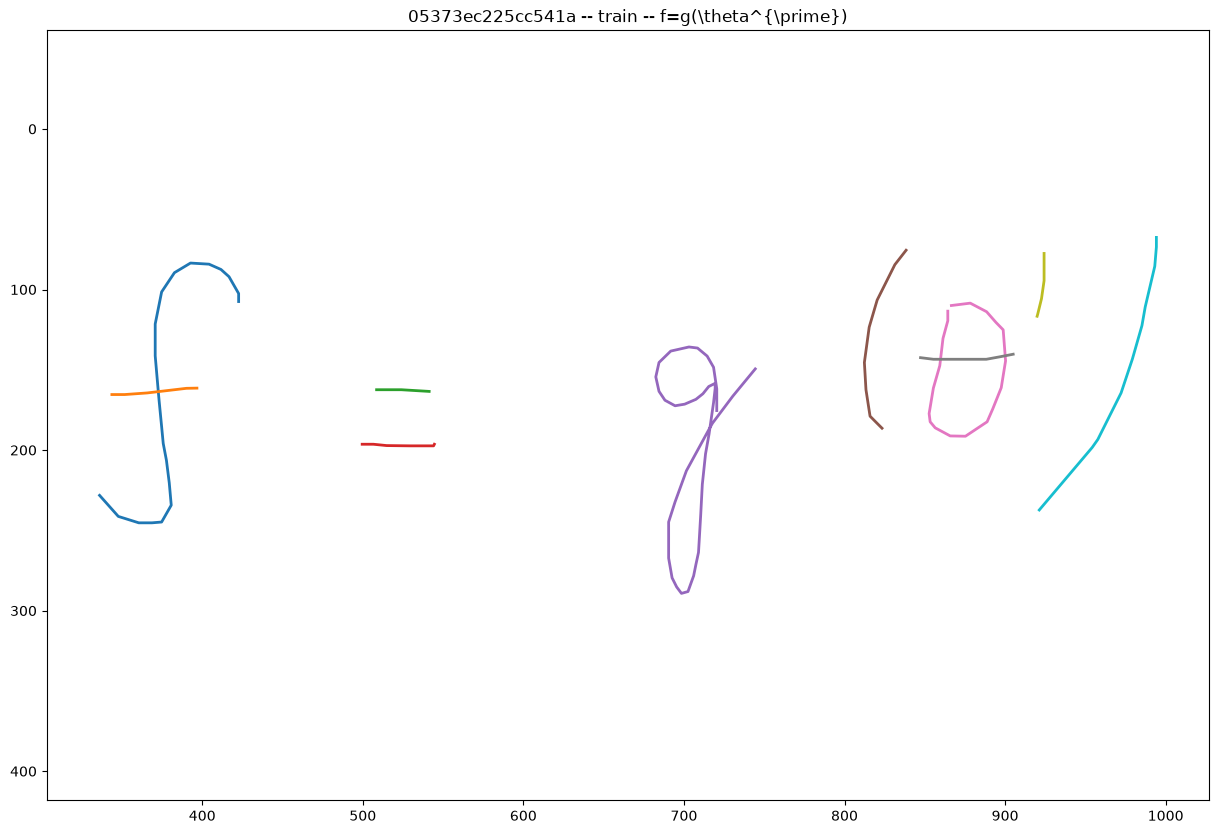

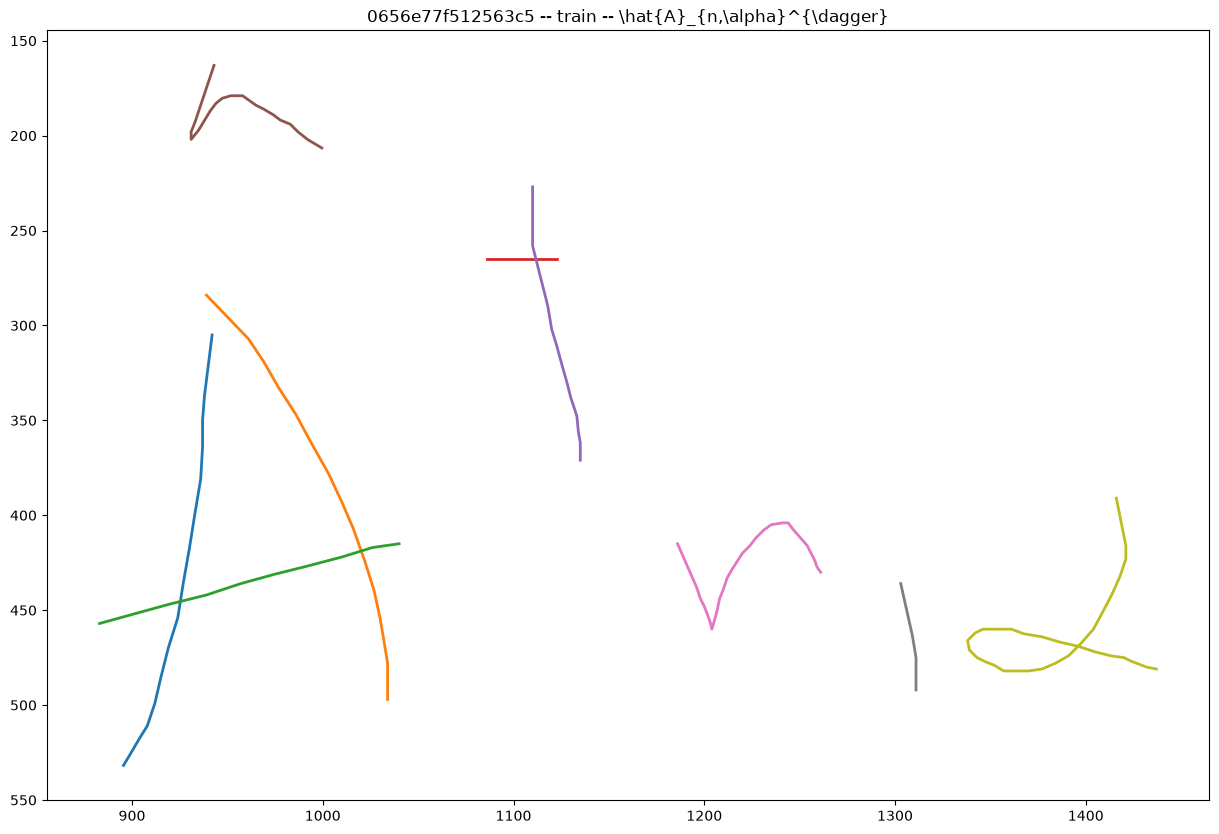

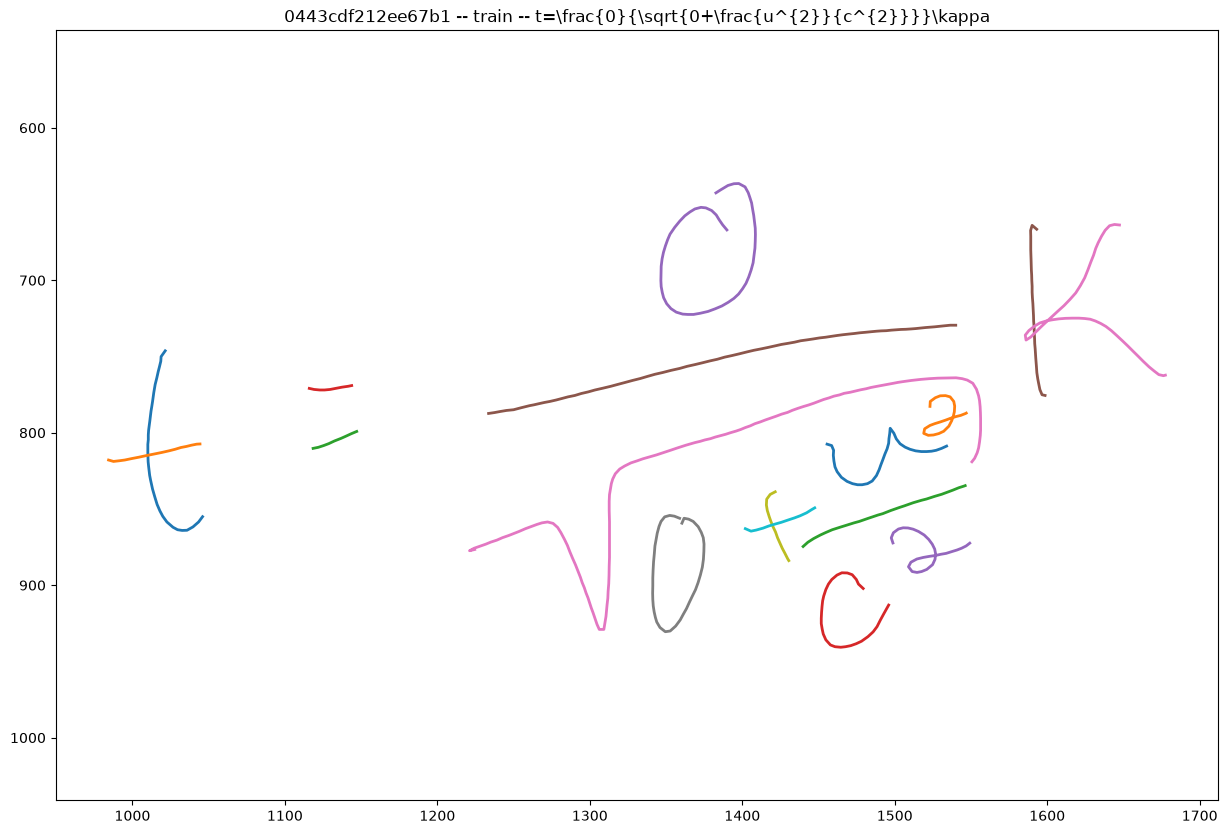

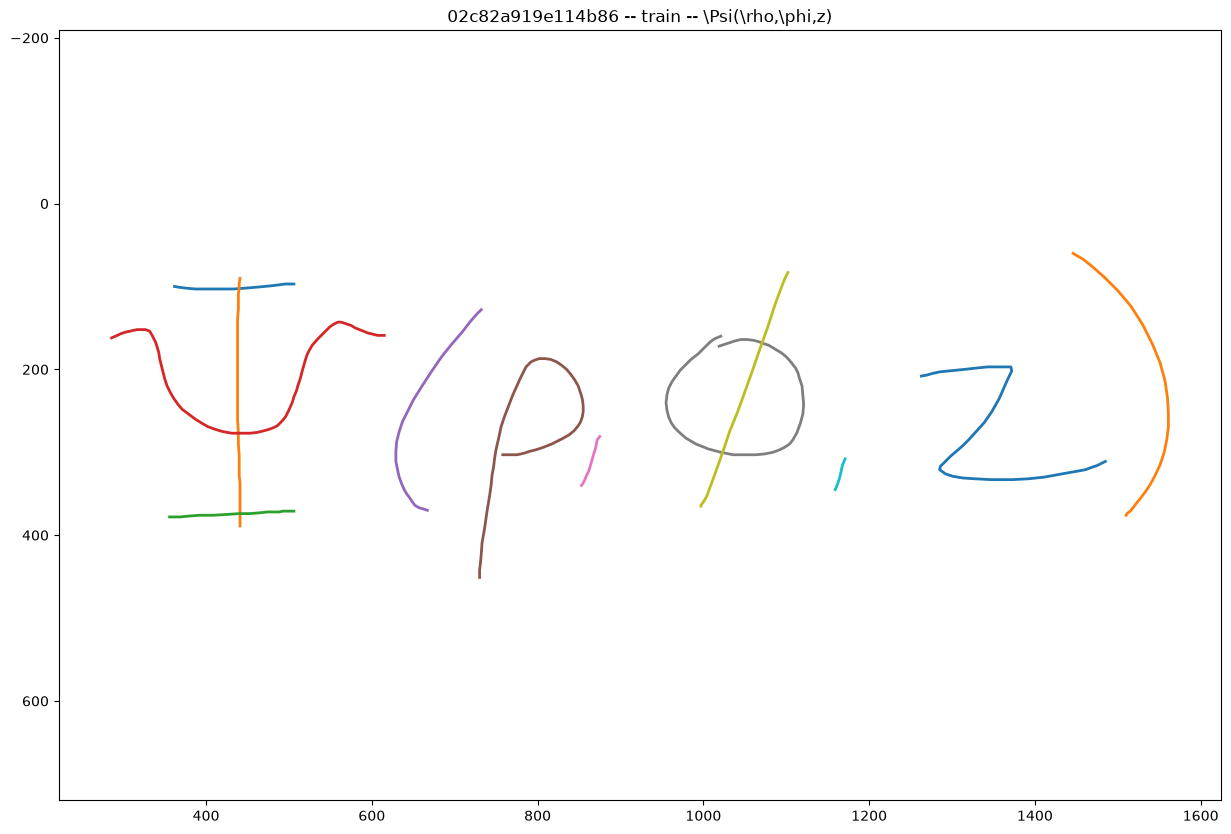

In [15]:
MATHWRITING_ROOT_DIR = "/Users/keshavsingh/Documents/Projects/NLP_LaTeX_Parser/ml/data/extracted_data/mathwriting-2024-excerpt"
# iterate and display 10 inks at a time
for i, filename in enumerate(os.listdir(os.path.join(MATHWRITING_ROOT_DIR, 'train'))):
  if i >= 10:
    break
  ink = read_inkml_file(os.path.join(MATHWRITING_ROOT_DIR, 'train', filename))
  display_ink(ink)

## Reading Bounding Box Files

These files contain bounding boxes with the symbol that should be displayed in it, plus the LaTeX string for the overall expression. The format used is JSONL: each line in the file is a separate JSON object containing all the bounding boxes for a single mathematical expression.

The code below shows how to turn each of these lines into a Python class.

In [16]:
@dataclasses.dataclass
class BoundingBox:
  """A bounding box for a single symbol."""
  # The symbol that should appear in the bounding box, in LaTeX notation.
  token: str
  # Definition of the bounding box.
  x_min: float
  y_min: float
  x_max: float
  y_max: float


@dataclasses.dataclass
class BoundingBoxes:
  """A set of bounding boxes for a complete mathematical expression."""
  # The complete (raw) LaTeX string.
  label: str
  # A normalized version of `label`.
  normalized_label: str|None
  # Bounding boxes for all symbols in the expression, in no particular order.
  bboxes: list[BoundingBox]


def read_bbox_file(filename: str, *, index: int=0) -> BoundingBoxes:
  """Reads a single bounding box from the input file."""
  with open(filename, "r") as f:
    for n, line in enumerate(f):
      if n < index:
        continue

      bboxes = json.loads(line)

      symbol_bboxes = []
      for bbox in bboxes['bboxes']:
        symbol_bboxes.append(BoundingBox(
            token=bbox['token'],
            x_min=bbox['xMin'],
            y_min=bbox['yMin'],
            x_max=bbox['xMax'],
            y_max=bbox['yMax']))

      return BoundingBoxes(
              label=bboxes['label'],
              normalized_label=bboxes.get('normalizedLabel', None),
              bboxes = symbol_bboxes)


def display_bboxes(bboxes: BoundingBoxes, *, figsize: tuple[int, int]=(15, 10)):
  """Displays a set of bounding boxes for debugging purposes."""
  fig = pl.figure(figsize=figsize)
  ax = fig.gca()
  x_min = float('inf')
  y_min = float('inf')
  x_max = -float('inf')
  y_max = -float('inf')
  for bbox in bboxes.bboxes:
    x_min = min(x_min, bbox.x_min)
    y_min = min(y_min, bbox.y_min)
    x_max = max(x_max, bbox.x_max)
    y_max = max(y_max, bbox.y_max)

    ax.add_patch(
        mpl_patches.Polygon(
            ((bbox.x_min,bbox.y_min),
            (bbox.x_min,bbox.y_max),
            (bbox.x_max,bbox.y_max),
            (bbox.x_max, bbox.y_min)),
            closed=True,
            facecolor='none',
            edgecolor='darkblue',
            linewidth=2))

  width = x_max - x_min
  height = y_max - y_min

  # We put the text in one go at the end to be able to scale it properly.
  for bbox in bboxes.bboxes:
    box_width = bbox.x_max - bbox.x_min
    box_height = bbox.y_max - bbox.y_min
    if bbox.token != r'\frac':
      ax.text(bbox.x_min+box_width/2,
              bbox.y_min+box_height/2,
              bbox.token,
              verticalalignment='center',
              horizontalalignment='center',
              fontsize=100000 / max(width, height))

  margin_ratio = 0.1
  ax.set_xlim(x_min-margin_ratio*width, x_max+margin_ratio*width)
  ax.set_ylim(y_max+margin_ratio*height, y_min-margin_ratio*height)
  pl.title(bboxes.normalized_label or bboxes.label)


## Extracting Individual Symbols

For the purpose of synthesizing inks from bounding boxes, isolated symbols are provided as inks. These were extracted from inks from the training set, and MathWriting contains all the information necessary to recompute this extraction.
The code below shows how to do it.


In [5]:
@dataclasses.dataclass
class InkPart:
  """A pointer to a part of an ink corresponding to a single symbol."""
  # Which sample the symbol is from. Ex: '00016221aae38d32'
  source_sample_id: str
  # Which symbol it is. Ex: '\sum'
  label: str
  # Indices of strokes in the source ink that cover the symbol.
  stroke_indices: list[int]


def read_symbols_file(filename: str) -> list[InkPart]:
  """Reads all the symbol definitions."""
  symbols = []
  with open(filename, "r") as f:
    for line in f:
      symbol_json = json.loads(line)
      symbols.append(InkPart(
          source_sample_id=symbol_json['sourceSampleId'],
          label=symbol_json['label'],
          stroke_indices=symbol_json['strokeIndices']))
  return symbols


def get_symbol_ink(symbol: InkPart) -> Ink:
  """Computes the actual ink from an InkPart object."""
  ink = read_inkml_file(
      os.path.join(MATHWRITING_ROOT_DIR, "train", f"{symbol.source_sample_id}.inkml"))
  strokes = [ink.strokes[i] for i in symbol.stroke_indices]
  return Ink(
      strokes=strokes,
      annotations={
          'label': symbol.label,
          'splitTagOriginal': ink.annotations['splitTagOriginal']})

## Ink Rasterization

This shows how to use Cairo for high-quality rendering of inks.

In [26]:
import sys
print(sys.executable)

/Users/keshavsingh/Documents/Projects/ml-mini-projects/.venv/bin/python


In [27]:
%%bash
export PATH="/opt/homebrew/bin:/usr/local/bin:$PATH"
brew install cairo pkg-config

To reinstall 1.18.6, run:
  brew reinstall cairo
To reinstall 3.0.10, run:
  brew reinstall pkgconf


In [28]:
import sys
!{sys.executable} -m pip install pycairo

  Using cached pycairo-1.29.2.tar.gz (666 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pycairo: filename=pycairo-1.29.2-cp315-cp315-macosx_26_0_arm64.whl size=112583 sha256=4122ce23a9dde3e2308d7b37d0fef07ef46b482e903ec415739581c707da767d
  Stored in directory: /Users/keshavsingh/Library/Caches/pip/wheels/e1/6e/b0/2b19990104afe0fd1163d3aa8309b24037c93f2099b63b54ef
Successfully built pycairo

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [29]:
!apt-get install libcairo2-dev libjpeg-dev libgif-dev
!pip install pycairo

zsh:1: command not found: apt-get

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [30]:
import cairo
import math
import PIL
import PIL.Image


def cairo_to_pil(surface: cairo.ImageSurface) -> PIL.Image.Image:
  """Converts a ARGB Cairo surface into an RGB PIL image."""
  size = (surface.get_width(), surface.get_height())
  stride = surface.get_stride()
  with surface.get_data() as memory:
    return PIL.Image.frombuffer(
        'RGB', size, memory.tobytes(), 'raw', 'BGRX', stride
    )


def render_ink(
    ink: Ink,
    *,
    margin: int = 10,
    stroke_width: float = 1.5,
    stroke_color: tuple[float, float, float] = (0.0, 0.0, 0.0),
    background_color: tuple[float, float, float] = (1.0, 1.0, 1.0),
) -> PIL.Image.Image:
  """Renders an ink as a PIL image using Cairo.

  The image size is chosen to fit the entire ink while having one pixel per
  InkML unit.

  Args:
    margin: size of the blank margin around the image (pixels)
    stroke_width: width of each stroke (pixels)
    stroke_color: color to paint the strokes with
    background_color: color to fill the background with

  Returns:
    Rendered ink, as a PIL image.
  """

  # Compute transformation to fit the ink in the image.
  xmin, ymin = np.vstack([stroke[:2].min(axis=1) for stroke in ink.strokes]).min(axis=0)
  xmax, ymax = np.vstack([stroke[:2].max(axis=1) for stroke in ink.strokes]).max(axis=0)
  width = int(xmax - xmin + 2*margin)
  height = int(ymax - ymin + 2*margin)

  shift_x = - xmin + margin
  shift_y = - ymin + margin

  def apply_transform(ink_x: float, ink_y: float):
    return ink_x + shift_x, ink_y + shift_y

  # Create the canvas with the background color
  surface = cairo.ImageSurface(cairo.FORMAT_ARGB32, width, height)
  ctx = cairo.Context(surface)
  ctx.set_source_rgb(*background_color)
  ctx.paint()

  # Set pen parameters
  ctx.set_source_rgb(*stroke_color)
  ctx.set_line_width(stroke_width)
  ctx.set_line_cap(cairo.LineCap.ROUND)
  ctx.set_line_join(cairo.LineJoin.ROUND)

  for stroke in ink.strokes:
    if len(stroke[0]) == 1:
      # For isolated points we just draw a filled disk with a diameter equal
      # to the line width.
      x, y = apply_transform(stroke[0, 0], stroke[1, 0])
      ctx.arc(x, y, stroke_width / 2, 0, 2 * math.pi)
      ctx.fill()

    else:
      ctx.move_to(*apply_transform(stroke[0,0], stroke[1,0]))

      for ink_x, ink_y in stroke[:2, 1:].T:
        ctx.line_to(*apply_transform(ink_x, ink_y))
      ctx.stroke()

  return cairo_to_pil(surface)

ink = read_inkml_file(os.path.join(MATHWRITING_ROOT_DIR, 'train', '0668dd347d600906.inkml'))

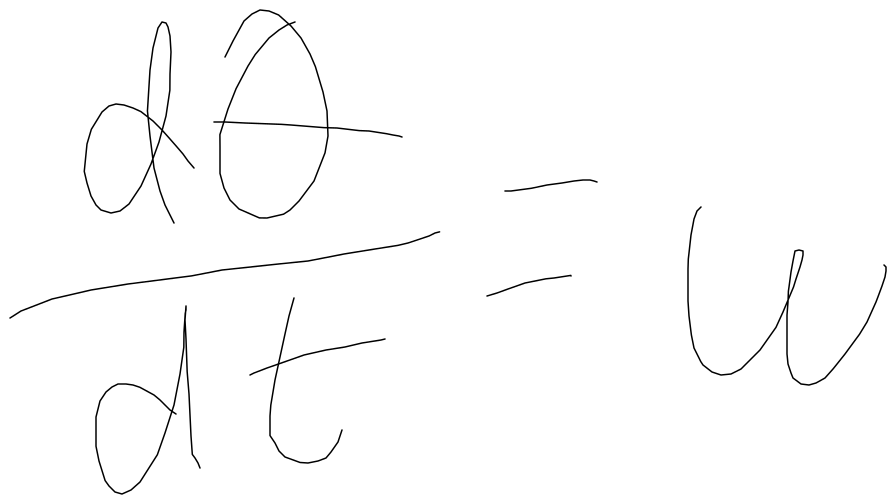

In [31]:
render_ink(ink)

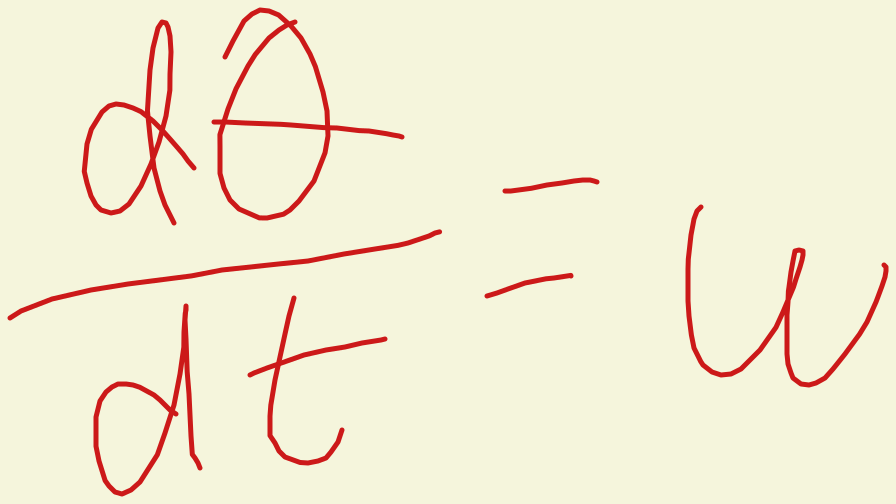

In [32]:
render_ink(
    ink,
    stroke_width=5.0,
    stroke_color=(.8, .1, .1),
    background_color=(.96, .96, .86),
  )

## Model Evaluation

A few functions to compute the character error rate for model performance evaluation.

### Tokenizer

Function to split a LaTeX expressions into tokens. These tokens can be used for model training or model evaluation.

In [33]:
_COMMAND_RE = re.compile(r'\\(mathbb{[a-zA-Z]}|begin{[a-z]+}|end{[a-z]+}|operatorname\*|[a-zA-Z]+|.)')


def tokenize_expression(s: str) -> list[str]:
  r"""Transform a Latex math string into a list of tokens.

  Tokens are strings that are meaningful in the context of Latex
  e.g. '1', r'\alpha', r'\frac'.

  Args:
    s: unicode input string (ex: r"\frac{1}{2}")

  Returns:
    tokens: list of tokens as unicode strings.
  """
  tokens = []
  while s:
    if s[0] == '\\':
      tokens.append(_COMMAND_RE.match(s).group(0))
    else:
      tokens.append(s[0])

    s = s[len(tokens[-1]) :]

  return tokens


# Example
print(tokenize_expression(r'\frac{\alpha}{2}\begin{matrix}1&0\\0&1\end{matrix}\not\in\mathbb{R}'))

['\\frac', '{', '\\alpha', '}', '{', '2', '}', '\\begin{matrix}', '1', '&', '0', '\\\\', '0', '&', '1', '\\end{matrix}', '\\not', '\\in', '\\mathbb{R}']


### CER Computation

Computation of the Character Error Rate.

In [34]:
!pip install jiwer
import jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [jiwer]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [46]:
def computeCer(truth_and_output: list[tuple[str, str]]):
  """Computes CER given pairs of ground truth and model output."""
  class TokenizeTransform(jiwer.transforms.AbstractTransform):
    def process_string(self, s: str):
      return tokenize_expression(r'{}'.format(s))

    def process_list(self, tokens: list[str]):
      return [self.process_string(token) for token in tokens]

  ground_truth, model_output = zip(*truth_and_output)

  return jiwer.cer(
            reference=list(ground_truth),
            hypothesis=list(model_output),
            reference_transform=TokenizeTransform(),
            hypothesis_transform=TokenizeTransform(),
      )

In [47]:
# Test data to run compute_cer().
# The first element is the model prediction, the second the ground truth.
examples = [
    (r'\sqrt{2}', r'\sqrt{2}'),  # 0 mistakes, 4 tokens
    (r'\frac{1}{2}', r'\frac{i}{2}'),  # 1 mistake, 7 tokens
    (r'\alpha^{2}', 'a^{2}'),  # 1 mistake, 5 tokens
    ('abc', 'def'),  # 3 mistakes, 3 tokens
]

# 5 mistakes for 19 tokens: 26.3% error rate.
print(f"{computeCer(examples)*100:.1f} %")

26.3 %


## ML Model (for realsies)


In [ ]:
import random

!pip install torch torchvision
import random

%pip install torch torchvision

import torch


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [52]:
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
IMG_H, IMG_W = 64, 256
SPLIT_DIR = lambda split: os.path.join(MATHWRITING_ROOT_DIR, split)


def ink_to_tensor(ink: Ink) -> torch.Tensor:
  """Renders an ink to a fixed-size grayscale tensor (1, H, W)."""
  img = render_ink(ink, stroke_width=3.0).convert("L")
  img = img.resize((IMG_W, IMG_H), PIL.Image.BILINEAR)
  arr = 1.0 - np.asarray(img, dtype=np.float32) / 255.0
  return torch.from_numpy(arr).unsqueeze(0)

# Build vocabulary from training split
def build_vocab(split: str = "train") -> dict:
  tokens = set()
  for fn in os.listdir(SPLIT_DIR(split)):
    ink_ = read_inkml_file(os.path.join(SPLIT_DIR(split), fn))
    label = ink_.annotations.get("normalizedLabel", ink_.annotations["label"])
    tokens.update(tokenize_expression(label))
  # index 0 is the CTC blank
  return {t: i + 1 for i, t in enumerate(sorted(tokens))}


def collate(batch):
  imgs, targets, labels = zip(*batch)
  lengths = torch.tensor([len(t) for t in targets], dtype=torch.long)
  return torch.stack(imgs), torch.cat(targets), lengths, labels


def greedy_decode(log_probs: torch.Tensor, inv_vocab: dict) -> list[str]:
  preds = log_probs.argmax(-1).cpu().numpy()
  results = []
  for seq in preds:
    out, prev = [], 0
    for p in seq:
      if p != prev and p != 0:
        out.append(inv_vocab[p])
      prev = p
    results.append("".join(out))
  return results


@torch.no_grad()
def evaluate(model, loader, inv_vocab, max_batches=None):
  model.eval()
  pairs = []
  for i, (imgs, _, _, labels) in enumerate(loader):
    if max_batches and i >= max_batches:
      break
    preds = greedy_decode(model(imgs.to(DEVICE)), inv_vocab)
    pairs.extend(zip(labels, preds))
  return computeCer(pairs)

NameError: name 'torch' is not defined

In [51]:
class MathDataset(Dataset):
  def __init__(self, split: str, vocab: dict):
    self.dir = SPLIT_DIR(split)
    self.files = sorted(f for f in os.listdir(self.dir) if f.endswith(".inkml"))
    self.vocab = vocab

  def __len__(self):
    return len(self.files)

  def __getitem__(self, idx):
    ink_ = read_inkml_file(os.path.join(self.dir, self.files[idx]))
    label = ink_.annotations.get("normalizedLabel", ink_.annotations["label"])
    toks = tokenize_expression(label)
    target = torch.tensor([self.vocab[t] for t in toks if t in self.vocab],
                          dtype=torch.long)
    return ink_to_tensor(ink_), target, len(target), label

NameError: name 'Dataset' is not defined

In [ ]:
class LightCRNN(nn.Module):
  """Small CNN + BiGRU with CTC output."""
  def __init__(self, num_classes: int):
    super().__init__()
    def block(i, o, pool):
      return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                           nn.ReLU(), nn.MaxPool2d(pool))
    self.cnn = nn.Sequential(
        block(1, 32, (2, 2)),    # 32 x 128
        block(32, 64, (2, 2)),   # 16 x 64
        block(64, 128, (2, 1)),  # 8 x 64
        block(128, 128, (2, 1)), # 4 x 64
    )
    self.rnn = nn.GRU(128 * 4, 128, num_layers=2, bidirectional=True,
                      batch_first=True, dropout=0.2)
    self.fc = nn.Linear(256, num_classes)

  def forward(self, x):
    f = self.cnn(x)                         # B, C, H, W
    b, c, h, w = f.shape
    f = f.permute(0, 3, 1, 2).reshape(b, w, c * h)
    out, _ = self.rnn(f)
    return self.fc(out).log_softmax(-1)     # B, T, K

In [ ]:
def train_model(epochs=20, batch_size=32, lr=1e-3, cer_threshold=0.30,
                save_path="latex_crnn.pt"):
  vocab = build_vocab("train")
  inv_vocab = {v: k for k, v in vocab.items()}
  train_ds = MathDataset("train", vocab)
  val_split = "valid" if os.path.isdir(SPLIT_DIR("valid")) else "test"
  val_ds = MathDataset(val_split, vocab)
  train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                        collate_fn=collate)
  val_dl = DataLoader(val_ds, batch_size=batch_size, collate_fn=collate)

  model = LightCRNN(len(vocab) + 1).to(DEVICE)
  opt = torch.optim.AdamW(model.parameters(), lr=lr)
  ctc = nn.CTCLoss(blank=0, zero_infinity=True)
  best_cer = float("inf")

  for epoch in range(epochs):
    model.train()
    total = 0.0
    for imgs, targets, tgt_lens, _ in train_dl:
      imgs = imgs.to(DEVICE)
      log_probs = model(imgs)                         # B, T, K
      in_lens = torch.full((imgs.size(0),), log_probs.size(1), dtype=torch.long)
      loss = ctc(log_probs.permute(1, 0, 2).cpu(), targets, in_lens, tgt_lens)
      opt.zero_grad()
      loss.backward()
      nn.utils.clip_grad_norm_(model.parameters(), 5.0)
      opt.step()
      total += loss.item()
    cer = evaluate(model, val_dl, inv_vocab)
    print(f"epoch {epoch+1}: loss={total/len(train_dl):.4f} val CER={cer*100:.1f}%")
    if cer < best_cer:
      best_cer = cer
      best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

  if best_cer <= cer_threshold:
    torch.save({"state_dict": best_state, "vocab": vocab,
                "img_size": (IMG_H, IMG_W), "cer": best_cer}, save_path)
    print(f"Exported weights to {save_path} (CER {best_cer*100:.1f}%)")
  else:
    print(f"Best CER {best_cer*100:.1f}% above threshold; weights not exported.")
  return model, vocab


model, vocab = train_model()